# Norfolk County | Exploratory data analysis


**Scope.** One redacted charge-level CSV. Main intake cohort uses recorded received dates in 2017–2025. Disposition trends use recorded disposition dates in 2017–2025 and retain dated outcomes preceding receipt. Timing analyses exclude negative intervals. Years are not inferred from IDs. For alignment with the earlier county notebooks, annual tables include 2017–2024 as separate rows.

Run all cells from this folder or its parent with Python, pandas, matplotlib and IPython. Blank values become **Missing**. Explicit codes such as U stay separate. Source labels and codes are preserved. The original CSV is read only.

This GitHub copy includes aggregate chart outputs. Open the figure gallery from the project README for a separate view. Local execution requires the project source extracts.

## Findings at a glance

- The extract has **216,832 rows, 93,295 case IDs, and 64,639 person IDs**. The median case has two charge rows. There are 21 extra identical rows and 66 extra rows sharing a charge slot. The row totals retain both.
- The median offense-to-receipt interval is **32 days** across 215,394 rows with nonnegative usable intervals. Receipt is the source's administrative date and its relationship to court filing is unverified.
- **26,172** rows show a disposition before receipt. The median negative interval is three days before receipt. Outcome counts retain these dated records and timing calculations exclude them.
- Race is blank on **32.4%** of source rows and sex on **11.7%**. Judge is blank on **97.9%** of dated outcome rows within 2017–2025. The extract lacks bail fields and a dedicated offense severity classification.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

filename = 'NFK-Data-final-2017-2025 redacted.csv'
source = Path(filename) if Path(filename).is_file() else Path('norfolk') / filename
sha256 = hashlib.sha256(source.read_bytes()).hexdigest()
raw = pd.read_csv(source, encoding='cp1252', dtype=str, keep_default_na=False)
d = raw.apply(lambda s: s.str.strip().replace('', 'Missing'))
d['record'] = d.index + 1  # One-based data-record ordinal after header.
YEARS = list(range(2017, 2026))
for field, alias, fmt in [
    ('Received Date','received','%m/%d/%Y'),
    ('Date Crm','offense','%Y-%m-%d %I:%M%p'),
    ('Date Dspstn','disposed','%Y-%m-%d %I:%M%p'),
    ('Date Exctn','execution','%Y-%m-%d %I:%M%p')
]:
    parsed = pd.to_datetime(d[field], format=fmt, errors='coerce')
    valid = parsed.between('1900-01-01','2026-11-06')
    d[alias] = parsed.where(valid)
    d[alias+'_quality'] = 'Valid'
    d.loc[d[field].eq('Missing'), alias+'_quality'] = 'Missing'
    d.loc[d[field].ne('Missing') & ~valid, alias+'_quality'] = 'Invalid / out of bounds'

d['received_year'] = d.received.dt.year.astype('Int64')
d['disposed_year'] = d.disposed.dt.year.astype('Int64')
d['disposition'] = d['Desc Dspstn']
cwof = d['Code Dspstn'].eq('PLEA') & d['Code Rsn Dspstn'].eq('CWOF')
d.loc[cwof,'disposition'] = 'CWOF (plea reason)'
d.loc[d['Code Dspstn'].eq('PLEA') & ~cwof,'disposition'] = 'Other recorded plea'
d['days_offense_received'] = (d.received - d.offense).dt.days
d['days_received_disposition'] = (d.disposed - d.received).dt.days
d['days_offense_disposition'] = (d.disposed - d.offense).dt.days
court_names = {'QDC':'Quincy', 'BDC':'Brookline', 'DDC':'Dedham',
               'SDC':'Stoughton','WDC':'Wrentham','NSC':'Norfolk Superior'}
d['court'] = d['Code Crt Lctn Disp'].map(court_names).fillna(d['Code Crt Lctn Disp'])
d['court_level'] = 'Other / unmapped'
d.loc[d.court.isin(list(court_names.values())[:5]),'court_level'] = 'District'
d.loc[d.court.eq('Norfolk Superior'),'court_level'] = 'Superior'
d.loc[d.court.eq('Missing'),'court_level'] = 'Missing'
window = d[d.disposed_year.isin(YEARS) & d['Code Dspstn'].ne('Missing')].copy()
chronological = window[window.days_received_disposition.ge(0)].copy()
cohort = d[d.received_year.isin(YEARS)].copy()
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
palette = ['#27647b','#dc8951','#719b81','#845e91','#b7575c','#8a8f98',
           '#a9b9c5','#9e7948','#434979','#72714b','#a87caa','#456a52']
def chart(data, title, ylabel, kind='bar', stacked=False, xlabel='', figsize=(10,4)):
    ax = data.plot(kind=kind, stacked=stacked, figsize=figsize, color=palette)
    ax.set(title=title, ylabel=ylabel, xlabel=xlabel)
    if kind == 'bar':
        ax.tick_params(axis='x', labelrotation=0)
    if ax.get_legend():
        ax.legend(bbox_to_anchor=(1.02,1), loc='upper left', title=None, fontsize=8)
    plt.tight_layout()
    plt.show()
    plt.close(ax.figure)
def table(frame, name, limit=16):
    frame.to_csv(out / (name + '.csv'))
    display(frame.head(limit).round(2))
def mix(frame, by, value, name, title, top=7):
    frequent = frame[value].value_counts().head(top).index.union(['Missing'], sort=False)
    shown = frame[value].where(frame[value].isin(frequent), 'Other recorded')
    counts = pd.crosstab(frame[by], shown)
    pct = counts.div(counts.sum(axis=1),axis=0).mul(100)
    table(pd.crosstab(frame[by],frame[value]),name+'_full_counts')
    table(pct,name+'_chart_pct')
    chart(pct,title,'Percent of rows',stacked=True)
def summary_days(x):
    usable = x[x.ge(0)]
    return pd.Series({'all_rows':len(x),'missing_or_invalid':x.isna().sum(),
                      'negative':x.lt(0).sum(),'usable':len(usable),
                      'mean':usable.mean(),'p25':usable.quantile(.25),
                      'median':usable.median(),'p75':usable.quantile(.75),
                      'p95':usable.quantile(.95),'max':usable.max()})

out = source.parent / 'norfolk_eda_outputs'
out.mkdir(exist_ok=True)

## 1. Grain, coverage and identifiers
Case ID maps to one person and one received date in this file. The charge slot is case ID + count + subcount. Retain all source rows for row composition, and count distinct slots for a sensitivity check. A conflicting slot may reflect versions or a data issue.

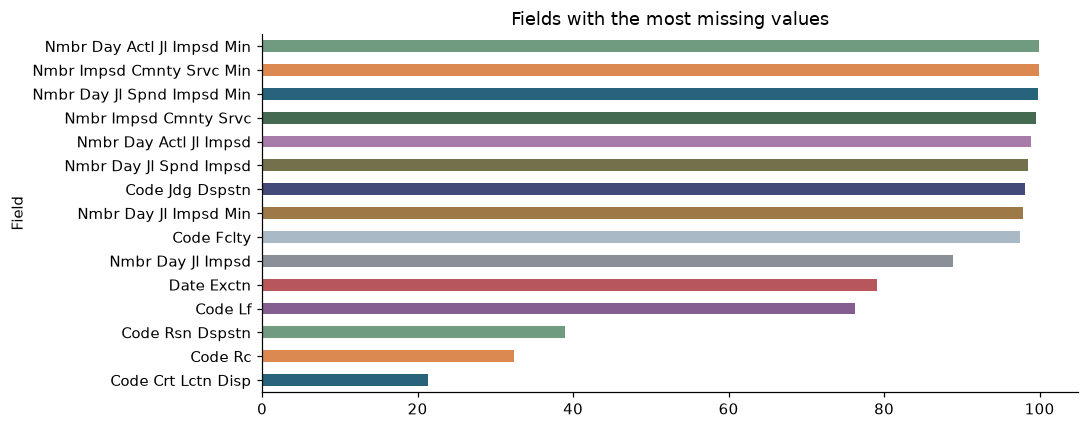

In [2]:
slot = ['Id Cs','Nmbr Cnt','Nmbr Sub Cnt']
case = d.groupby('Id Cs').agg(person=('Id Prsn','first'), received=('received','first'),
                              status=('Case Status','first'), case_type=('Case Type','first'),
                              charge_rows=('record','size'))
case['distinct_slots'] = d.drop_duplicates(slot).groupby('Id Cs').size()
case['year'] = case.received.dt.year
assert d.groupby('Id Cs')['Id Prsn'].nunique().max() == 1
assert d.groupby('Id Cs')['Received Date'].nunique().max() == 1
print(f'{len(d):,} source rows, {raw.shape[1]} fields, {len(case):,} case IDs and {case.person.nunique():,} person IDs')
print(f'{raw.duplicated().sum():,} identical extra rows and {d.duplicated(slot).sum():,} extra rows sharing a slot')
table(case[['charge_rows','distinct_slots']].describe(), 'charges_per_case_summary')
quality = pd.DataFrame({'nonblank_distinct':d[raw.columns].where(d[raw.columns].ne('Missing')).nunique(),
                        'missing_n':d[raw.columns].eq('Missing').sum()})
quality['missing_pct'] = quality.missing_n / len(d) * 100
table(quality, 'field_profile', 39)
chart(quality.missing_pct.nlargest(15).sort_values(), 'Fields with the most missing values','Field',kind='barh')
for field in ['Code Sex','Code Rc','Case Status','Case Type','Crime Type','Code Ofcr Agncy',
              'Code Chrg','Desc Chrg','Code Dspstn','Desc Dspstn','Code Rsn Dspstn','Code Lf',
              'Code Jdg Dspstn','Code Crt Lctn Disp','Code Fclty']:
    table(d[field].value_counts().rename('rows').to_frame(), 'frequency_'+field.lower().replace(' ','_'), 5)

## 2. Dates and anomalies
Very old offense dates can reflect historical allegations. Keep them visible and examine the upper tail separately. Keep dates beyond the review date and impossible date strings in the audit, outside interval calculations. Use receipt as the recorded intake milestone. The CSV has no verified court filing or arraignment date.

In [3]:
date_audit = []
for field, key in [('Received Date','received'),('Date Crm','offense'),
                   ('Date Dspstn','disposed'),('Date Exctn','execution')]:
    for label, n in d[key+'_quality'].value_counts().items():
        date_audit.append({'field':field,'quality':label,'rows':n})
    print(field, d[key].min().date(), d[key].max().date())
    examples = d.loc[d[key+'_quality'].eq('Invalid / out of bounds'),field].value_counts()
    if len(examples):
        table(examples.rename('rows').to_frame(), 'invalid_'+key, 8)
table(pd.DataFrame(date_audit), 'date_quality')
intervals = ['days_offense_received','days_received_disposition','days_offense_disposition']
table(pd.DataFrame({c:summary_days(d[c]) for c in intervals}).T,'date_intervals')
flags = pd.DataFrame({
    'duplicate full record after first':raw.duplicated(),
    'charge slot appears more than once':d.duplicated(slot, keep=False),
    'offense date before 2017':d.offense.lt('2017-01-01'),
    'offense after receipt':d.days_offense_received.lt(0),
    'disposition before receipt':d.days_received_disposition.lt(0),
    'disposition before offense':d.days_offense_disposition.lt(0),
    'disposition date in 2026':d.disposed.dt.year.eq(2026),
    'outcome code without valid date':d['Code Dspstn'].ne('Missing') & d.disposed.isna(),
    'valid disposition date without outcome code':d['Code Dspstn'].eq('Missing') & d.disposed.notna(),
    'DISP status without outcome code':d['Case Status'].eq('DISP') & d['Code Dspstn'].eq('Missing'),
    'non-DISP status with outcome code':d['Case Status'].ne('DISP') & d['Code Dspstn'].ne('Missing')
})
table(flags.sum().rename('flagged_rows').to_frame(),'anomaly_counts')
negative = d.days_received_disposition.lt(0)
print(f"Median gap among negative receipt-to-disposition intervals: {d.loc[negative,'days_received_disposition'].median():.0f} days")
table(pd.crosstab(d.disposition,negative),'negative_interval_by_outcome',25)
table(pd.crosstab(d.court,negative),'negative_interval_by_court')
flag_records = flags.loc[flags.any(axis=1)].copy()
flag_records.index = d.loc[flag_records.index,'record']
flag_records.to_csv(out / 'record_flags_no_identifiers.csv')
conflicts = {c:int(d[d[c].ne('Missing')].groupby('Id Cs')[c].nunique().gt(1).sum())
             for c in ['Received Date','Case Type','Case Status','Code Sex','Code Rc','Code Crt Lctn Disp','Code Ofcr Agncy']}
table(pd.Series(conflicts, name='cases_with_multiple_nonmissing_values').to_frame(),'case_field_conflicts')

## 3. Intake volume, charge composition and concentration
The source includes open and disposed cases. Annual receipts measure the recorded intake cohort. Counts and subcounts describe recorded charge slots. Person concentration describes records in this extract and does not establish reoffending.

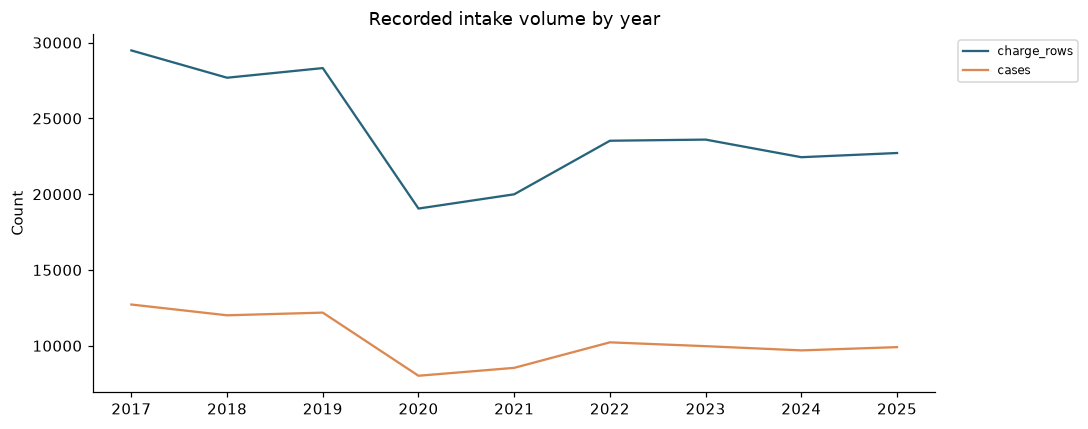

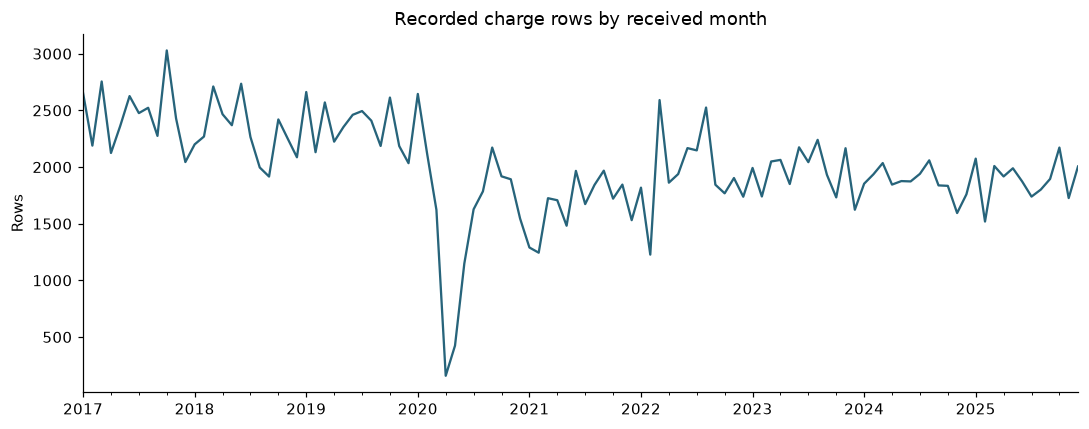

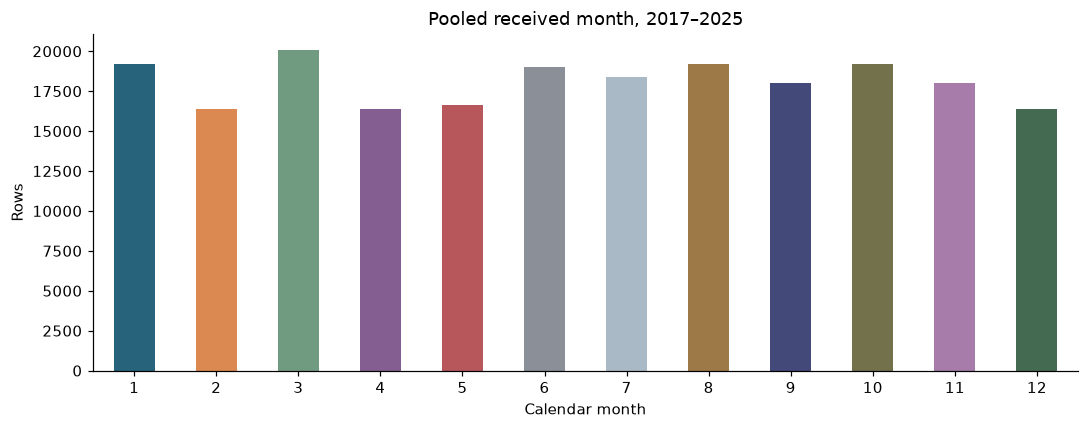

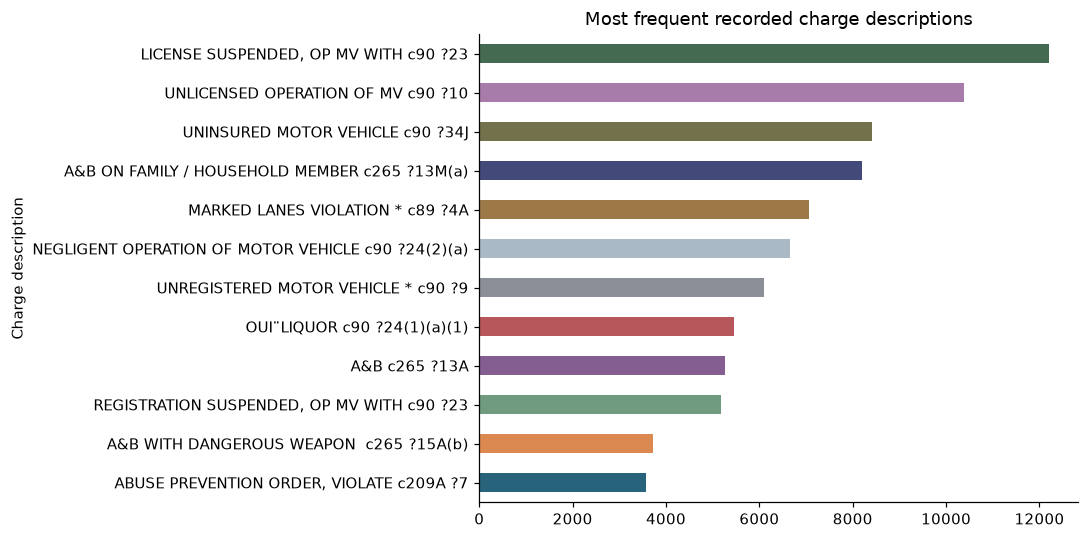

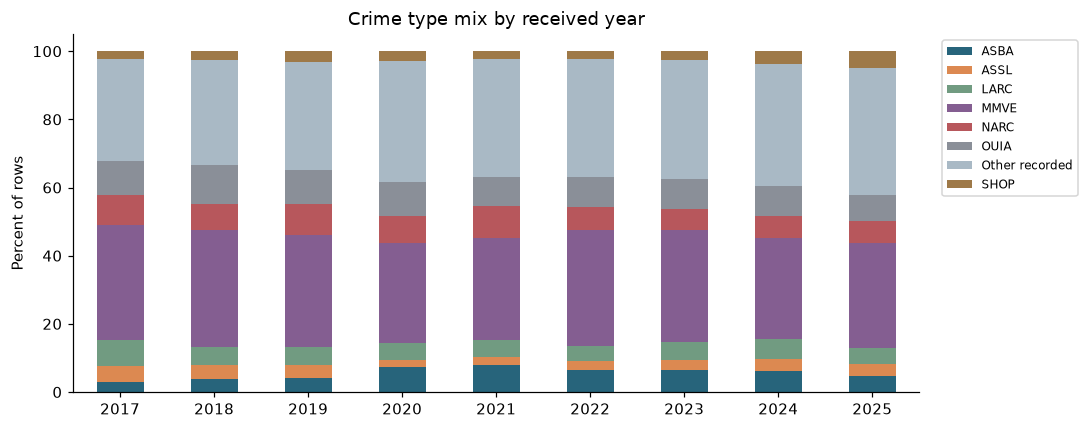

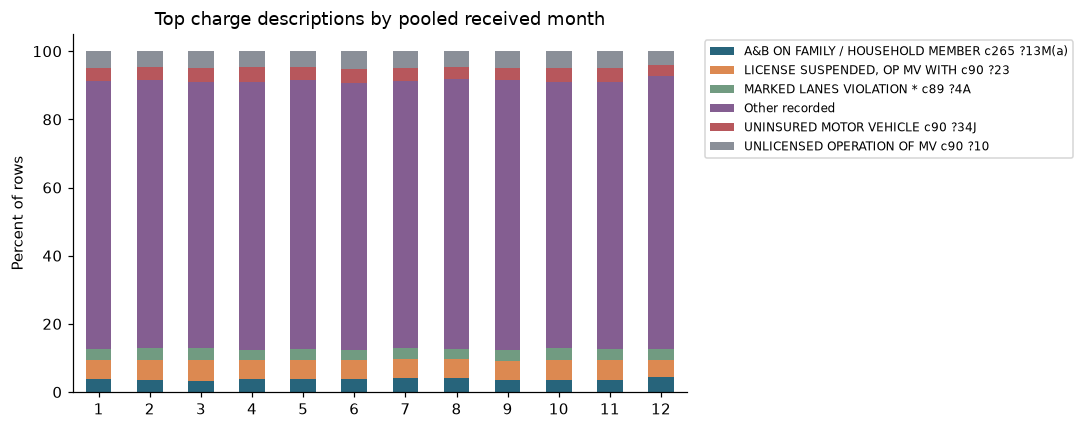

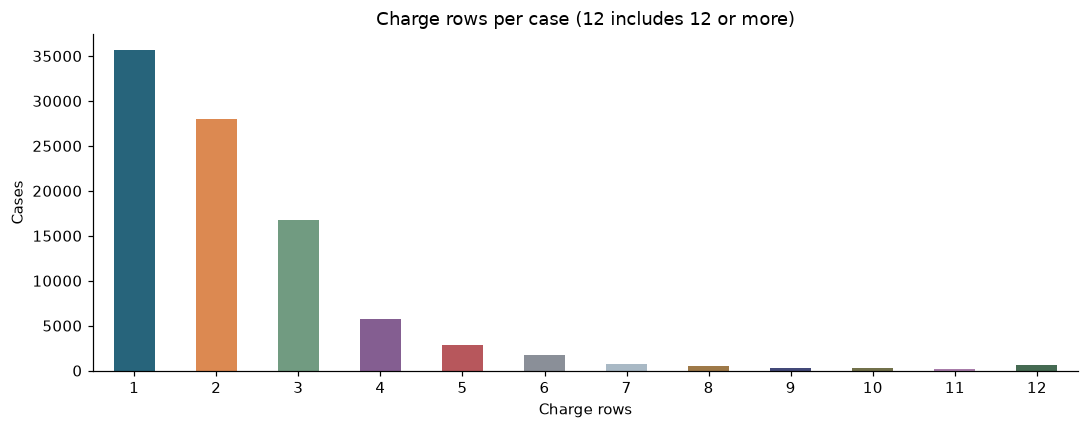

In [4]:
annual = cohort.groupby('received_year').agg(charge_rows=('record','size'),
              cases=('Id Cs','nunique'), people=('Id Prsn','nunique'))
annual['case_change_from_2017_pct'] = annual.cases.div(annual.cases.loc[2017]).sub(1).mul(100)
table(annual,'annual_receipts')
chart(annual[['charge_rows','cases']], 'Recorded intake volume by year','Count',kind='line')
monthly = cohort.groupby(cohort.received.dt.to_period('M')).size()
table(monthly.rename('rows').to_frame(),'monthly_receipts',12)
chart(monthly,'Recorded charge rows by received month','Rows',kind='line')
monthly_season = cohort.groupby(cohort.received.dt.month).size()
chart(monthly_season,'Pooled received month, 2017–2025','Rows',xlabel='Calendar month')
chart(d['Desc Chrg'].value_counts().head(12).sort_values().rename(index=lambda x:x[:62]),
      'Most frequent recorded charge descriptions','Charge description',kind='barh',figsize=(10,5))
mix(cohort,'received_year','Crime Type','crime_type_by_received_year','Crime type mix by received year')
cohort['received_month'] = cohort.received.dt.month
mix(cohort,'received_month','Desc Chrg','description_by_calendar_month','Top charge descriptions by pooled received month',5)
table(pd.crosstab(cohort.received.dt.to_period('M'),cohort['Desc Chrg']),
      'description_by_year_month', 4)
table(pd.crosstab(cohort.received_year,cohort['Desc Chrg']),'description_by_received_year', 4)
table(d.groupby('Id Prsn').agg(charge_rows=('record','size'),cases=('Id Cs','nunique'))
       .groupby('cases').agg(people=('charge_rows','size'),mean_charge_rows=('charge_rows','mean')),
      'person_concentration_no_identifiers')
print('Maximum rows for one redacted person:', d.groupby('Id Prsn').size().max())
chart(case.charge_rows.clip(upper=12).value_counts().sort_index(),
      'Charge rows per case (12 includes 12 or more)','Cases',xlabel='Charge rows')

## 4. Demographics, case type and agency
Code Rc and Code Sex are person fields attached to charge records. Their codebook and coding history are unverified. Case Type and Crime Type describe different source dimensions. There is no dedicated offense-class field. Agency code identifies a recorded agency, with no validated incident location.

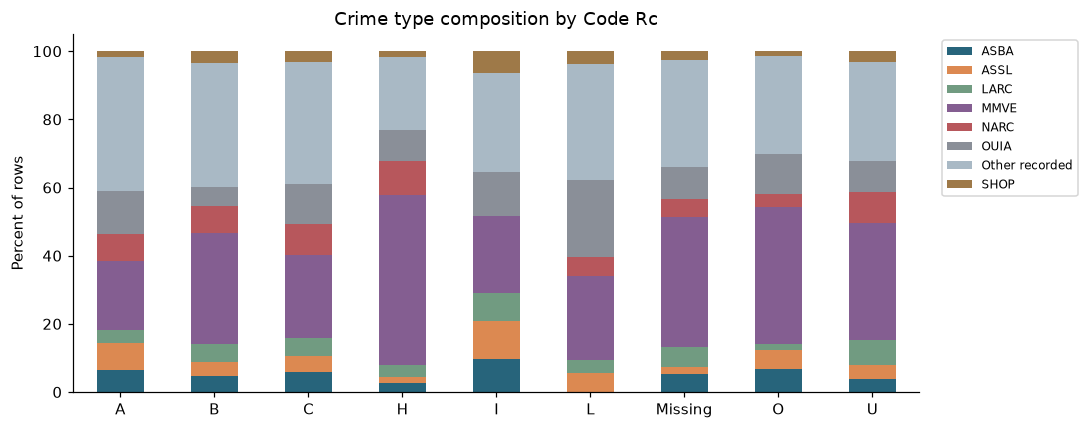

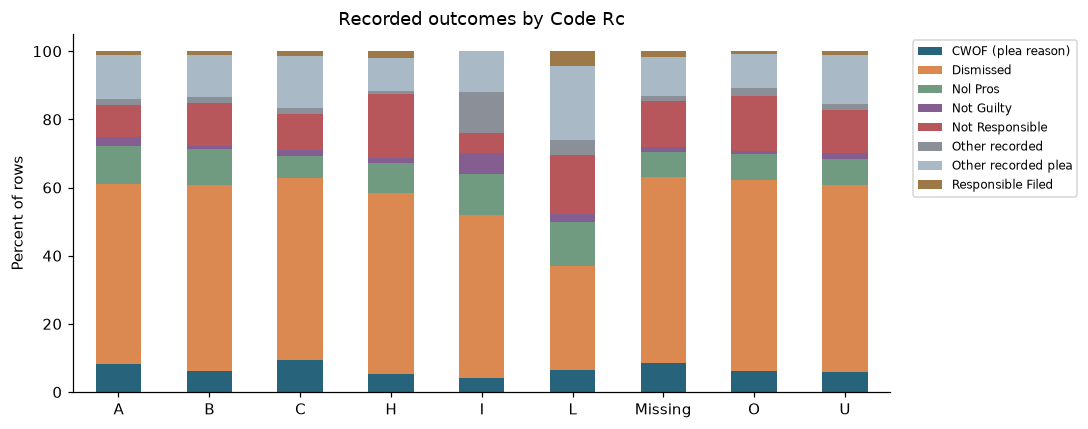

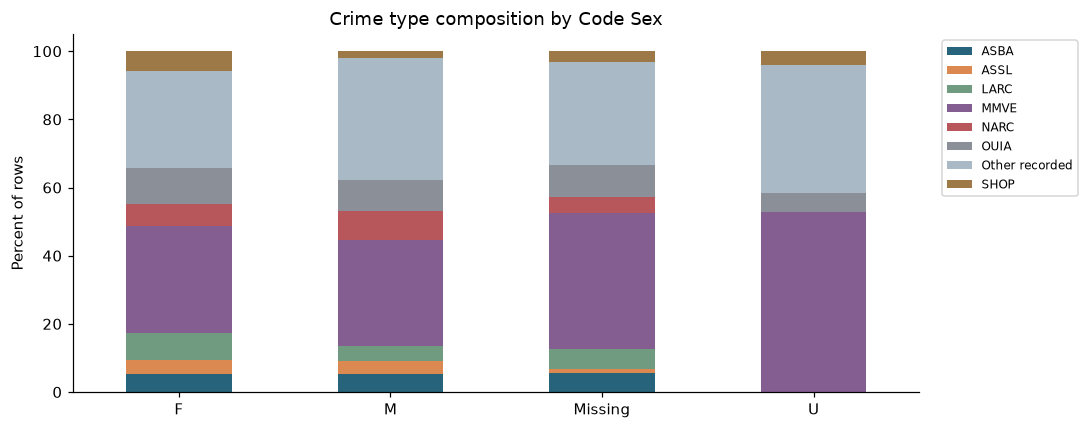

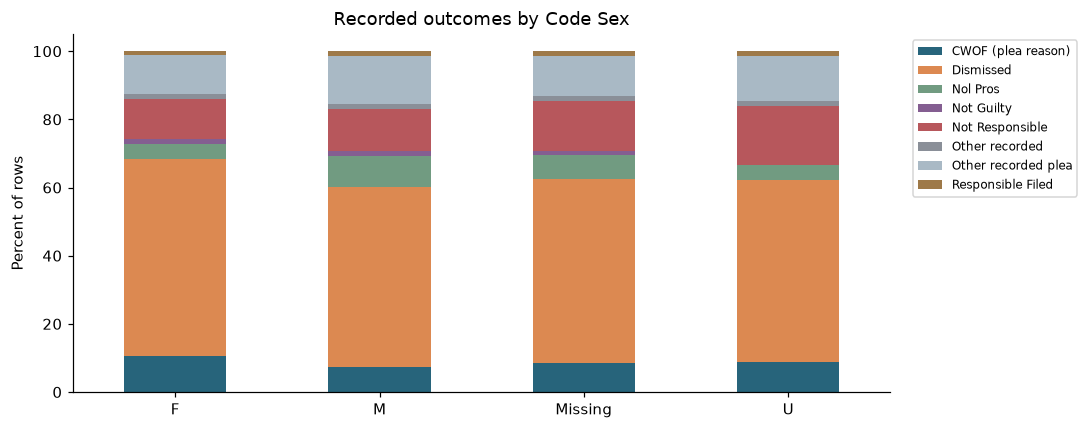

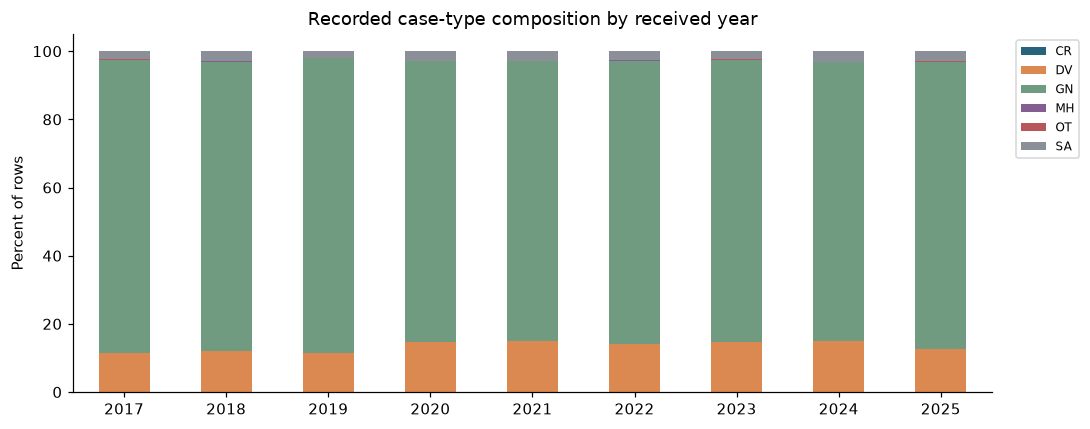

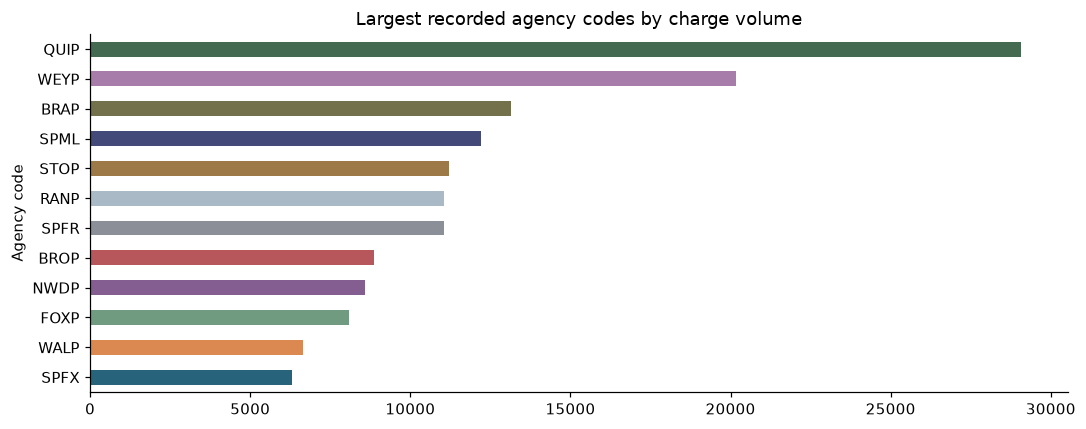

In [5]:
for demo in ['Code Rc','Code Sex']:
    table(pd.crosstab(d[demo],d['Desc Chrg']),'description_by_'+demo[-2:].lower(), 10)
    mix(d,demo,'Crime Type','crime_type_by_'+demo[-2:].lower(),f'Crime type composition by {demo}')
    mix(window,demo,'disposition','outcome_by_'+demo[-2:].lower(),f'Recorded outcomes by {demo}')
mix(cohort,'received_year','Case Type','case_type_by_year','Recorded case-type composition by received year',6)
agency = d.groupby('Code Ofcr Agncy').agg(rows=('record','size'),cases=('Id Cs','nunique'))
table(agency.sort_values('rows',ascending=False),'agency_volume')
chart(agency.rows.nlargest(12).sort_values(),'Largest recorded agency codes by charge volume','Agency code',kind='barh')
table(pd.crosstab(d['Code Ofcr Agncy'],d['Crime Type']),'agency_crime_type_counts')

## 5. Recorded disposition and court patterns
Each outcome here belongs to a charge row. The outcome field reports Plea. The CWOF reason identifies a separately displayed subset. The remaining plea rows can include other pathways and do not provide a verified conviction count. Civil responsibility and transfer outcomes remain separate. Court mappings are inferred from the five district abbreviations and NSC. Judge coverage is audited before interpreting the recorded subset.

In [6]:
print(f'{len(window):,} dated outcome rows within the disposition window')
table(d.groupby(['Code Dspstn','Desc Dspstn','Code Rsn Dspstn','Code Lf']).size()
       .sort_values(ascending=False).rename('rows').to_frame(),'outcome_reason_finding_crosswalk')
table(d.disposition.value_counts().rename('rows').to_frame(),'outcomes_all_rows',25)
mix(window,'disposed_year','disposition','disposition_by_year','Charge outcome mix by disposition year')
table(pd.crosstab(window['Desc Chrg'],window.disposition),'description_by_disposition')
table(pd.crosstab(window['Crime Type'],window.disposition),'crime_type_by_disposition')
mix(window,'court','disposition','disposition_by_court','Recorded outcome mix by court code')
judge = window.groupby('Code Jdg Dspstn').agg(rows=('record','size'),cases=('Id Cs','nunique'))
table(judge.sort_values('rows',ascending=False),'judge_coverage')
table(pd.crosstab(window['Code Jdg Dspstn'],window.disposition),'judge_outcome_counts')
print(f"Missing judge in {window['Code Jdg Dspstn'].eq('Missing').mean():.1%} of dated outcome rows. Judge comparisons reflect selective recording.")
timing = chronological.groupby('Case Type')['days_received_disposition'].apply(summary_days).unstack()
table(timing,'receipt_to_charge_disposition_by_case_type')
chart(timing['median'],'Median receipt-to-charge-disposition days','Days',xlabel='Case type')
case_last = chronological.groupby('Id Cs').agg(last_observed=('disposed','max'))
case_last = case_last.join(case[['received','status','distinct_slots']])
case_last['days'] = (case_last.last_observed-case_last.received).dt.days
closed = case_last[case_last.status.eq('DISP')].copy()
later_cases = d.loc[d.disposed.gt('2025-12-31'),'Id Cs']
negative_cases = d.loc[d.days_received_disposition.lt(0),'Id Cs']
closed = closed.loc[~closed.index.isin(later_cases) & ~closed.index.isin(negative_cases)].copy()
closed['slots'] = closed.distinct_slots.clip(upper=8)
table(closed.groupby('slots').days.apply(summary_days).unstack(),'receipt_to_last_by_charge_slots')
chart(closed.groupby('slots').days.median(),'Median receipt to last observed disposition','Days',
      xlabel='Distinct charge slots (8 includes 8 or more)')

## 6. Sentence fields and bail availability
Positive terms are recorded amounts. Imposed, suspended and actual fields have different meanings. A positive actual jail field is a source marker. It does not establish time served, and blanks leave custody status undetermined. Unit codes remain visible, including codes outside ordinary time units. The CSV has no bail request, bail set, posting, release, or pretrial custody history.

In [7]:
terms = [c for c in raw.columns if c.startswith('Nmbr ') and c+' Unt' in raw.columns]
term_rows = []
for field in terms:
    amount = pd.to_numeric(d[field],errors='coerce')
    units = d[field+' Unt']
    term_rows.append({'field':field,'missing':d[field].eq('Missing').sum(),
                      'non_numeric_nonblank':(d[field].ne('Missing') & amount.isna()).sum(),
                      'zero':amount.eq(0).sum(),'negative':amount.lt(0).sum(),
                      'positive':amount.gt(0).sum(),
                      'positive_missing_unit':(amount.gt(0)&units.eq('Missing')).sum(),
                      'unit_without_amount':(units.ne('Missing')&amount.isna()).sum()})
    table(pd.crosstab(amount.gt(0).map({True:'Positive',False:'Other or missing'}),units),
          'units_'+field.lower().replace(' ','_'), 3)
table(pd.DataFrame(term_rows),'sentence_field_coverage')
field = 'Nmbr Day Actl Jl Impsd'
n = pd.to_numeric(d[field], errors='coerce')
d['actual_jail_marker'] = 'Other recorded value'
d.loc[d[field].eq('Missing'),'actual_jail_marker'] = 'Missing'
d.loc[n.gt(0),'actual_jail_marker'] = 'Positive recorded term'
table(pd.crosstab(d.disposition,d.actual_jail_marker),'actual_term_by_disposition')
table(pd.crosstab(d['Code Rc'],d.actual_jail_marker),'actual_term_by_race_code')
table(pd.crosstab(d['Code Sex'],d.actual_jail_marker),'actual_term_by_sex_code')
table(d.loc[n.gt(0)].groupby([field+' Unt',field]).size().rename('rows').to_frame(),
      'positive_actual_amount_by_original_unit')

In [8]:
assert hashlib.sha256(source.read_bytes()).hexdigest() == sha256
print('Source SHA-256:', sha256)
print('Aggregate CSV outputs:', len(list(out.glob('*.csv'))))

## Selected results from this run

### annual receipts

| received_year | charge_rows | cases | people | case_change_from_2017_pct |
| --- | --- | --- | --- | --- |
| 2017 | 29486 | 12722 | 10962 | 0 |
| 2018 | 27685 | 12011 | 10459 | -5.59 |
| 2019 | 28322 | 12188 | 10516 | -4.2 |
| 2020 | 19054 | 8022 | 7015 | -36.94 |
| 2021 | 19994 | 8544 | 7324 | -32.84 |
| 2022 | 23528 | 10227 | 8617 | -19.61 |
| 2023 | 23603 | 9974 | 8529 | -21.6 |
| 2024 | 22442 | 9696 | 8271 | -23.79 |

[Full results table](published-results/annual_receipts.csv)
